# 00 · Data map — what the scraper actually produced

`indexclone` (`scraper.py`) writes two different things into this checkout, and
they are easy to confuse, so this notebook starts by mapping them.

| tree | what it is | how it was produced | how many |
| --- | --- | --- | --- |
| `outputs/` | a **listing inventory** — one row per document the crawler *saw* on the real portals, with its published name, size and date | `tools/snapshot_inventory.py`, a `--dry-run`-style crawl of listing pages captured on 2026-09-28 | 127 documents, 5 sites |
| `outputs-replica/` | a **complete run** — download → SHA-256 → de-duplicate → hardlink → report → resume, with real bytes over HTTP | `tools/replica_demo.py` against a local replica of the six dialects | 39 documents, 6 sites, 5.1 MiB |

Nothing here touches the network: every number below is read back out of the
report files. Run **Cell → Run All** (or `python3 notebooks/run_notebooks.py`)
to rebuild every figure.

In [1]:
import os
import sys

# Make the shared loader importable whether the kernel started in the repo root
# or in notebooks/.
CWD = os.getcwd()
for _cand in (os.path.join(CWD, "notebooks"), CWD, os.path.dirname(CWD)):
    if os.path.isfile(os.path.join(_cand, "dadosabertos_data.py")):
        sys.path.insert(0, _cand)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import dadosabertos_data as d

plt = d.setup_plots()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

print("repository root :", d.ROOT)
print("loader module   :", os.path.dirname(d.__file__))
for _t in d.TREES:
    print(f"  {_t:<16} {len(d.site_dirs(_t))} site folders")

repository root : /home/user/dadosabertos
loader module   : /home/user/dadosabertos/notebooks
  outputs          5 site folders
  outputs-replica  6 site folders


## 1 · Which report files exist, and how big are they

`scraper.py` writes the same set of files into every `<site>/_reports/` folder.
A report that is *missing* is meaningful — `candidate_duplicates.csv`, for
instance, only appears when a dry run found same-size / similar-name pairs.

In [2]:
def describe(row):
    if not row["exists"]:
        return "—"
    if row["file"].endswith(".csv"):
        return f"{int(row['rows'])} rows"
    if row["file"] == "state.json":
        return f"{int(row['rows'])} urls"
    return d.human_bytes(row["bytes"])


def map_of(tree):
    inv = d.report_inventory(tree)
    inv["cell"] = [describe(r) for _, r in inv.iterrows()]
    wide = inv.pivot(index="site", columns="file", values="cell")
    wide = wide.reindex(columns=[f for f in d.REPORT_FILES if f in wide.columns])
    wide.columns.name = None
    return wide.fillna("—")


display(Markdown("**`outputs/`** — the real listing inventory"))
display(map_of("outputs"))
display(Markdown("**`outputs-replica/`** — the full run over the local replica"))
display(map_of("outputs-replica"))

**`outputs/`** — the real listing inventory

,manifest.csv,manifest.json,duplicates.csv,candidate_duplicates.csv,errors.log,summary.json,state.json
site,,,,,,,
comissaodaverdade.al.sp.gov.br,42 rows,16.9 KiB,0 rows,—,0 B,574 B,0 urls
dados.cvm.gov.br,18 rows,7.9 KiB,0 rows,23 rows,0 B,749 B,0 urls
dadosabertos.pgfn.gov.br,6 rows,2.9 KiB,0 rows,—,0 B,597 B,0 urls
macau.rn.gov.br,8 rows,4.3 KiB,0 rows,—,0 B,682 B,0 urls
valiprev.sp.gov.br,53 rows,23.6 KiB,0 rows,49 rows,0 B,585 B,0 urls


**`outputs-replica/`** — the full run over the local replica

,manifest.csv,manifest.json,duplicates.csv,candidate_duplicates.csv,errors.log,summary.json,state.json
site,,,,,,,
comissaodaverdade.al.sp.gov.br,8 rows,4.9 KiB,2 rows,—,0 B,820 B,8 urls
dados.cvm.gov.br,5 rows,3.4 KiB,1 rows,—,0 B,855 B,5 urls
dadosabertos.pgfn.gov.br,7 rows,4.6 KiB,3 rows,—,0 B,760 B,7 urls
geofiles.caxias.rs.gov.br,6 rows,3.6 KiB,0 rows,—,0 B,714 B,6 urls
macau.rn.gov.br,5 rows,3.8 KiB,1 rows,—,0 B,761 B,5 urls
valiprev.sp.gov.br,8 rows,5.9 KiB,2 rows,—,0 B,795 B,8 urls


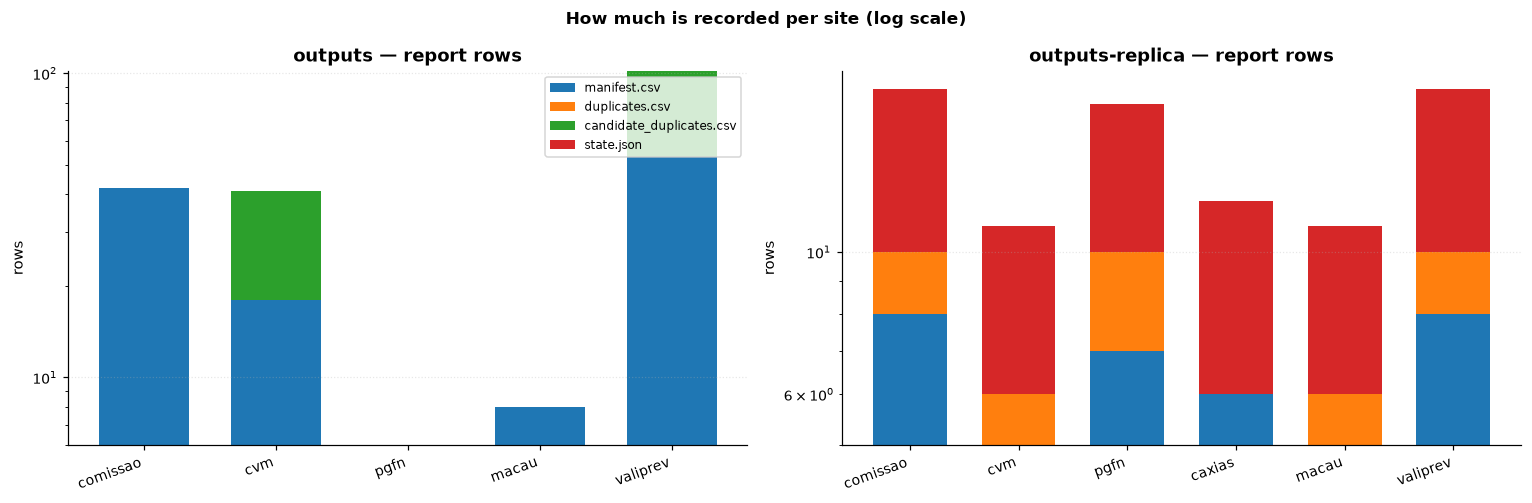

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=False)
files = ["manifest.csv", "duplicates.csv", "candidate_duplicates.csv", "state.json"]

for ax, tree in zip(axes, d.TREES):
    inv = d.report_inventory(tree)
    tab = inv[inv["file"].isin(files)].pivot_table(
        index="site", columns="file", values="rows", aggfunc="sum", fill_value=0
    )
    tab = tab.reindex(columns=[f for f in files if f in tab.columns])
    bottom = None
    for col in tab.columns:
        vals = tab[col].to_numpy(dtype=float)
        ax.bar(range(len(tab)), vals, bottom=bottom, label=col, width=0.68)
        bottom = vals if bottom is None else bottom + vals
    ax.set_xticks(range(len(tab)))
    ax.set_xticklabels([d.short_site(s) for s in tab.index], rotation=20, ha="right")
    ax.set_title(f"{tree} — report rows")
    ax.set_ylabel("rows")
    ax.set_yscale("log")
    ax.grid(axis="x", visible=False)

axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("How much is recorded per site (log scale)", fontweight="bold")
fig.tight_layout()
plt.show()

## 2 · The global roll-up, side by side

`_reports/global.json` is the same totals table the top-level README prints.
The two columns answer different questions: *what is out there* (`outputs`)
versus *what the crawler actually did* (`outputs-replica`).

In [4]:
totals = pd.DataFrame(
    {
        "outputs": d.load_global("outputs").get("totals", {}),
        "outputs-replica": d.load_global("outputs-replica").get("totals", {}),
    }
)

METRIC_LABEL = {
    "sites": "sites",
    "documents_discovered": "documents discovered",
    "documents_fetched": "documents fetched",
    "duplicates_collapsed": "duplicates collapsed",
    "candidate_duplicates": "candidate duplicates (heuristic)",
    "errors": "errors",
    "bytes_downloaded": "bytes downloaded",
    "bytes_saved_by_dedupe": "bytes never fetched",
}

count_keys = [
    "sites",
    "documents_discovered",
    "documents_fetched",
    "duplicates_collapsed",
    "candidate_duplicates",
    "errors",
]
byte_keys = ["bytes_downloaded", "bytes_saved_by_dedupe"]

show = totals.loc[[k for k in count_keys + byte_keys if k in totals.index]].copy()
show.index = [METRIC_LABEL.get(k, k) for k in show.index]
show["outputs"] = show["outputs"].astype("int64")
show["outputs-replica"] = show["outputs-replica"].astype("int64")
show["outputs (pretty)"] = [
    d.human_bytes(v) if k in byte_keys else f"{v:,}"
    for k, v in zip(show.index, show["outputs"])
]
show["replica (pretty)"] = [
    d.human_bytes(v) if k in byte_keys else f"{v:,}"
    for k, v in zip(show.index, show["outputs-replica"])
]
display(show)

,outputs,outputs-replica,outputs (pretty),replica (pretty)
sites,5,6,5,6
documents discovered,127,39,127,39
documents fetched,0,39,0,39
duplicates collapsed,0,9,0,9
candidate duplicates (heuristic),72,0,72,0
errors,0,0,0,0
bytes downloaded,0,5345336,0,"5,345,336"
bytes never fetched,0,1448368,0,"1,448,368"


### Two different numbers are called "bytes downloaded"

`global.json → totals.bytes_downloaded` counts the bytes of the documents that
were **stored** (5.1 MiB). The per-site `summary.json → bytes_downloaded_this_run`
counts everything that **crossed the network**, including the 374 KiB of
duplicates that had to be fetched before their hash could collapse them (5.5 MiB).
Both are correct; they answer different questions. Notebook 02 reconciles them
line by line.

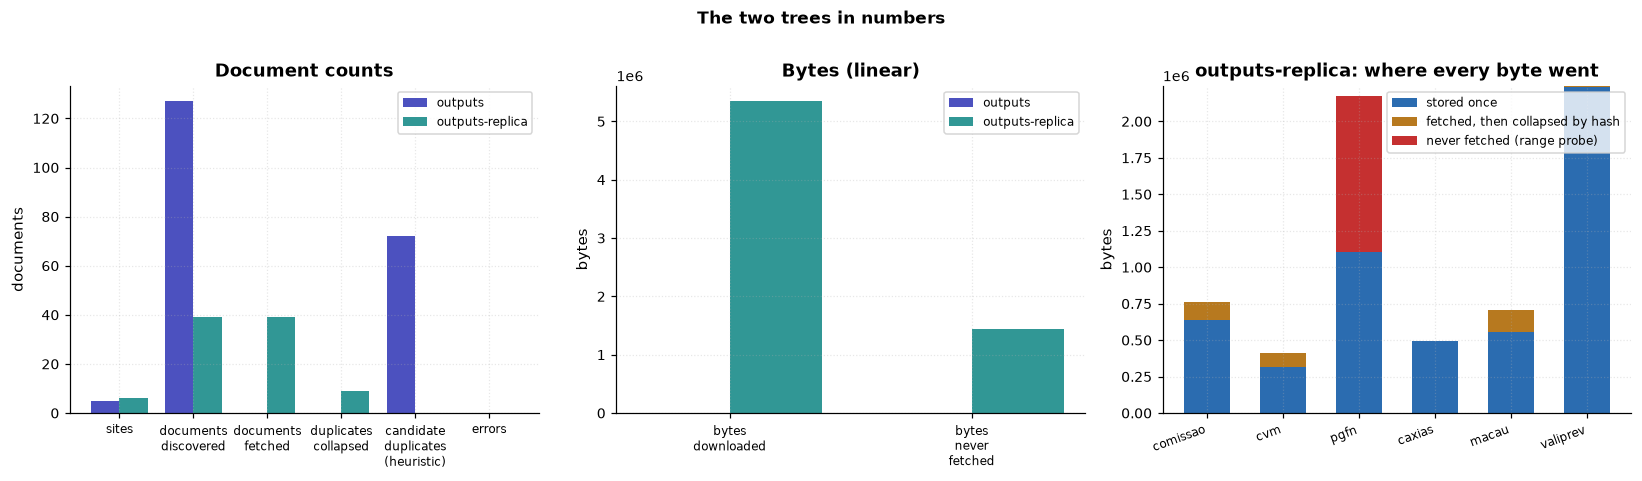

replica: 5.1 MiB stored · 374.4 KiB fetched and then collapsed · 1.0 MiB never fetched at all
         5.5 MiB crossed the network out of a 6.5 MiB tree — see notebook 02 for the full reconciliation


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

counts = totals.loc[[k for k in count_keys if k in totals.index]]
x = range(len(counts))
w = 0.38
axes[0].bar([i - w / 2 for i in x], counts["outputs"], w, label="outputs", color="#4c51bf")
axes[0].bar(
    [i + w / 2 for i in x], counts["outputs-replica"], w, label="outputs-replica", color="#319795"
)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels([METRIC_LABEL.get(k, k).replace(" ", "\n") for k in counts.index], fontsize=8)
axes[0].set_ylabel("documents")
axes[0].set_title("Document counts")
axes[0].legend(fontsize=8)

bycol = totals.loc[[k for k in byte_keys if k in totals.index]]
x2 = range(len(bycol))
axes[1].bar([i - w / 2 for i in x2], bycol["outputs"], w, label="outputs", color="#4c51bf")
axes[1].bar(
    [i + w / 2 for i in x2], bycol["outputs-replica"], w, label="outputs-replica", color="#319795"
)
axes[1].set_xticks(list(x2))
axes[1].set_xticklabels([METRIC_LABEL.get(k, k).replace(" ", "\n") for k in bycol.index], fontsize=8)
axes[1].set_ylabel("bytes")
axes[1].set_title("Bytes (linear)")
axes[1].legend(fontsize=8)

# where the replica's bytes actually went
summary = d.load_summary("outputs-replica")
dups = d.load_duplicates("outputs-replica")
sites = list(summary["site"])


def by_method(method, label):
    return (
        dups[dups["method"] == method]
        .groupby("site")["size"]
        .sum()
        .reindex(sites)
        .fillna(0)
        .to_numpy(dtype=float)
    )


stored_b = summary.set_index("site")["documents_bytes"].reindex(sites).fillna(0).to_numpy(dtype=float)
fetched_dup = by_method("sha256", "fetched then collapsed")
never_b = by_method("range-probe", "never fetched")

axes[2].bar(sites, stored_b, 0.6, label="stored once", color="#2b6cb0")
axes[2].bar(sites, fetched_dup, 0.6, bottom=stored_b, label="fetched, then collapsed by hash", color="#b7791f")
axes[2].bar(sites, never_b, 0.6, bottom=stored_b + fetched_dup, label="never fetched (range probe)", color="#c53030")
axes[2].set_xticks(range(len(sites)))
axes[2].set_xticklabels([d.short_site(s) for s in sites], rotation=20, ha="right", fontsize=8)
axes[2].set_ylabel("bytes")
axes[2].set_title("outputs-replica: where every byte went")
axes[2].legend(fontsize=8)

fig.suptitle("The two trees in numbers", fontweight="bold")
fig.tight_layout()
plt.show()

print(
    f"replica: {d.human_bytes(stored_b.sum())} stored · "
    f"{d.human_bytes(fetched_dup.sum())} fetched and then collapsed · "
    f"{d.human_bytes(never_b.sum())} never fetched at all"
)
print(
    f"         {d.human_bytes(stored_b.sum() + fetched_dup.sum())} crossed the network "
    f"out of a {d.human_bytes(stored_b.sum() + fetched_dup.sum() + never_b.sum())} tree "
    f"— see notebook 02 for the full reconciliation"
)

## 3 · The audit trail: every listing page, as fetched

`<site>/_index/pages/` keeps the raw HTML of each listing the crawler parsed.
That is what makes a run re-auditable — you can diff a report against the page
that produced it.

In [6]:
pages = pd.concat([d.index_pages(t) for t in d.TREES], ignore_index=True)
piv = pages.pivot_table(
    index="site", columns="tree", values="path", aggfunc="count", fill_value=0
)
piv_bytes = pages.pivot_table(
    index="site", columns="tree", values="bytes", aggfunc="sum", fill_value=0
)
piv = piv.reindex(columns=[c for c in d.TREES if c in piv.columns])
piv_bytes = piv_bytes.reindex(columns=[c for c in d.TREES if c in piv_bytes.columns])

summary_out = pd.DataFrame(
    {
        "pages (outputs)": piv.get("outputs", 0),
        "pages (replica)": piv.get("outputs-replica", 0),
        "html bytes (outputs)": piv_bytes.get("outputs", 0).map(d.human_bytes),
        "html bytes (replica)": piv_bytes.get("outputs-replica", 0).map(d.human_bytes),
    }
)
display(summary_out)
print("saved listing pages in total:", int(piv.to_numpy().sum()))

,pages (outputs),pages (replica),html bytes (outputs),html bytes (replica)
site,,,,
comissaodaverdade.al.sp.gov.br,1,1,6.4 KiB,1.0 KiB
dados.cvm.gov.br,5,4,9.8 KiB,5.1 KiB
dadosabertos.pgfn.gov.br,2,4,4.3 KiB,1.8 KiB
geofiles.caxias.rs.gov.br,0,5,0 B,2.0 KiB
macau.rn.gov.br,3,5,6.8 KiB,2.0 KiB
valiprev.sp.gov.br,1,5,17.8 KiB,5.3 KiB


saved listing pages in total: 36


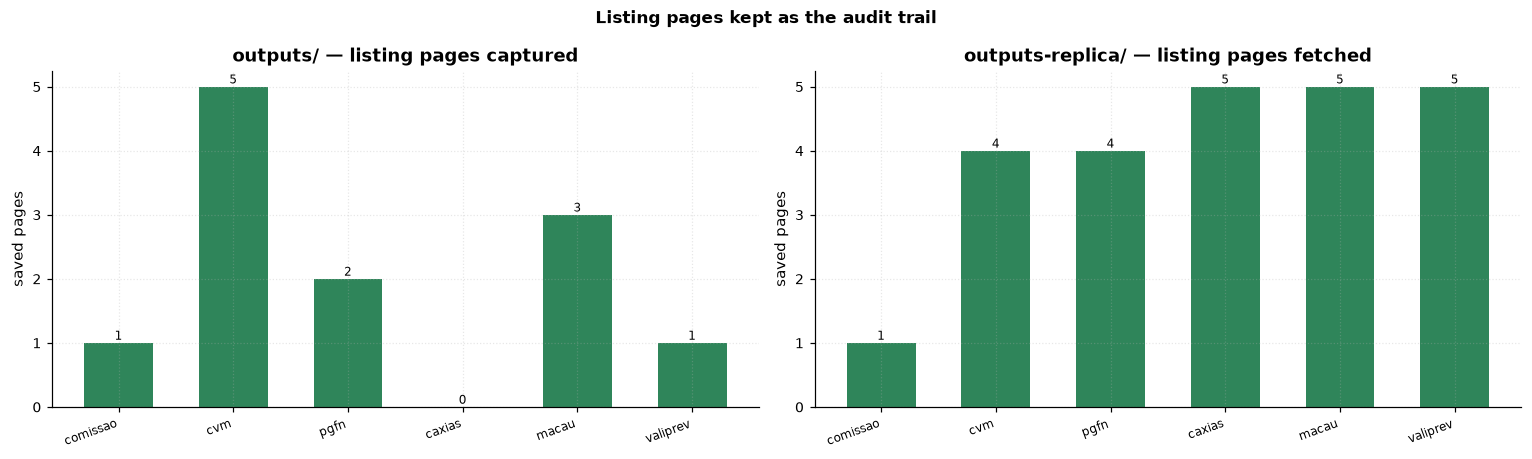

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sites = list(piv.index)
x = range(len(sites))
w = 0.38
for ax, col, title in (
    (axes[0], "outputs", "outputs/ — listing pages captured"),
    (axes[1], "outputs-replica", "outputs-replica/ — listing pages fetched"),
):
    ax.bar(x, piv[col].to_numpy(dtype=float), 0.6, color="#2f855a")
    ax.set_xticks(list(x))
    ax.set_xticklabels([d.short_site(s) for s in sites], rotation=20, ha="right", fontsize=8)
    ax.set_ylabel("saved pages")
    ax.set_title(title)
    for i, v in enumerate(piv[col].to_numpy(dtype=float)):
        ax.text(i, v + 0.05, str(int(v)), ha="center", fontsize=8)

fig.suptitle("Listing pages kept as the audit trail", fontweight="bold")
fig.tight_layout()
plt.show()

## Where to go next

| notebook | question it answers |
| --- | --- |
| `01_inventory_explorer.ipynb` | what are the 127 real documents — sizes, types, publication dates? |
| `02_replica_run.ipynb` | what did the full run cost, and where did de-duplication pay off? |
| `03_duplicates.ipynb` | which documents are re-publications of each other, and how was that decided? |
| `04_audit_health.ipynb` | can I trust the reports — do the bytes on disk match them? |
| `05_explorer_playground.ipynb` | slice any of the above with plain Python knobs |